# Practical 1: Feature Engineering (Missing Values, Encoding, Scaling)

**Subject:** Machine Learning  |  **Type:** Data preprocessing

## Aim
Apply basic feature engineering techniques such as handling missing values, encoding categorical variables and scaling numerical attributes on a suitable open-access dataset, to prepare a clean and model-ready dataset for machine learning analysis.

## Dataset
**Titanic** (open access, loaded with `seaborn.load_dataset('titanic')`, 891 passengers). It is ideal because it has:
- missing values (`age`, `deck`, `embarked`)
- categorical columns (`sex`, `embarked`, `class`, `who`)
- numerical columns on very different scales (`age` 0-80, `fare` 0-512)

*If there is no internet, the notebook falls back to a small synthetic messy dataset with the same structure, so every cell still runs.*

## Steps
1. Load and inspect the data
2. Handle missing values
3. Encode categorical variables
4. Scale numerical features
5. Split into train/test **before** fitting the scaler (avoids data leakage)
6. Verify the dataset is model-ready

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## Step 1: Load and inspect the data

In [2]:
def make_fallback(n=891, seed=0):
    # Synthetic messy data with the same columns as Titanic (used only if download fails)
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({
        "survived": rng.integers(0, 2, n),
        "pclass": rng.choice([1, 2, 3], n, p=[0.24, 0.21, 0.55]),
        "sex": rng.choice(["male", "female"], n, p=[0.65, 0.35]),
        "age": np.clip(rng.normal(30, 14, n), 0.5, 80).round(1),
        "sibsp": rng.integers(0, 4, n),
        "parch": rng.integers(0, 3, n),
        "fare": np.round(rng.lognormal(3, 1, n), 2),
        "embarked": rng.choice(["S", "C", "Q"], n, p=[0.72, 0.19, 0.09]),
    })
    d["class"] = d["pclass"].map({1: "First", 2: "Second", 3: "Third"})
    d["who"] = np.where(d["age"] < 16, "child", np.where(d["sex"] == "male", "man", "woman"))
    d["adult_male"] = (d["who"] == "man")
    d["deck"] = rng.choice(list("ABCDEFG"), n)
    d["embark_town"] = d["embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"})
    d["alive"] = d["survived"].map({0: "no", 1: "yes"})
    d["alone"] = (d["sibsp"] + d["parch"]) == 0
    d.loc[rng.choice(n, 177, replace=False), "age"] = np.nan
    d.loc[rng.choice(n, 687, replace=False), "deck"] = np.nan
    d.loc[rng.choice(n, 2, replace=False), "embarked"] = np.nan
    d.loc[d["embarked"].isna(), "embark_town"] = np.nan
    return d

try:
    df = sns.load_dataset("titanic")
    print("Loaded real Titanic dataset")
except Exception as e:
    print("Download failed, using synthetic fallback:", type(e).__name__)
    df = make_fallback()

print("Shape:", df.shape)
df.head()

Loaded real Titanic dataset
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Count and visualise missing values

In [10]:
missing = df.isnull().sum()
print(pd.DataFrame({"missing": missing})[missing > 0])

             missing
age              177
embarked           2
deck             688
embark_town        2


## Step 2: Handle missing values

| Column | missing | Strategy | Why |
|---|---|---|---|
| `deck` | 688 | **Drop column** | Too much missing; filling would invent data |
| `age` | 177 | **Median** | Numeric and skewed; median is robust to outliers |
| `embarked`, `embark_town` | 2 | **Mode** | Categorical; most frequent value |

In [11]:
data = df.copy()

# 1. Drop column with too many missing values
data = data.drop(columns=["deck"])

# 2. Numeric column -> median
data["age"] = data["age"].fillna(data["age"].median())

# 3. Categorical columns -> mode
for col in ["embarked", "embark_town"]:
    data[col] = data[col].fillna(data[col].mode()[0])

print("Total missing values left:", data.isnull().sum().sum())

Total missing values left: 0


## Step 3: Encode categorical variables

- **Label encoding**: converts categories to integers. Good for binary columns (`sex`).
- **One-hot encoding**: one 0/1 column per category. Good for nominal columns (`embarked`, `class`, `who`) because it does not imply any order.
- `drop_first=True` removes one dummy column to avoid the **dummy variable trap** (multicollinearity).
- Duplicate columns (`alive` = `survived`, `embark_town` = `embarked`, `pclass` = `class`) are dropped.

In [12]:
data = data.drop(columns=["alive", "embark_town", "class"])   # redundant duplicates

# Boolean columns -> int
for col in ["adult_male", "alone"]:
    data[col] = data[col].astype(int)

# Label encoding for binary column
le = LabelEncoder()
data["sex"] = le.fit_transform(data["sex"])
print("Label encoding classes:", dict(zip(le.classes_, le.transform(le.classes_))))

# One-hot encoding for nominal columns
data = pd.get_dummies(data, columns=["embarked", "who"], drop_first=True, dtype=int)

print(data.dtypes)
data.head()

Label encoding classes: {'female': 0, 'male': 1}
survived        int64
pclass          int64
sex             int32
age           float64
sibsp           int64
parch           int64
fare          float64
adult_male      int32
alone           int32
embarked_Q      int32
embarked_S      int32
who_man         int32
who_woman       int32
dtype: object


,survived,pclass,sex,age,sibsp,parch,fare,adult_male,alone,embarked_Q,embarked_S,who_man,who_woman
0,0,3,1,22.0,1,0,7.2500,1,0,0,1,1,0
1,1,1,0,38.0,1,0,71.2833,0,0,0,0,0,1
2,1,3,0,26.0,0,0,7.9250,0,1,0,1,0,1
3,1,1,0,35.0,1,0,53.1000,0,0,0,1,0,1
4,0,3,1,35.0,0,0,8.0500,1,1,0,1,1,0


## Step 4: Scale numerical features

Look at the ranges first. `fare` is far larger than `age`, so distance-based and gradient-based algorithms would be dominated by `fare`.

In [13]:
num_cols = ["age", "fare"]
print(data[num_cols].describe().round(2))

          age    fare
count  891.00  891.00
mean    29.36   32.20
std     13.02   49.69
min      0.42    0.00
25%     22.00    7.91
50%     28.00   14.45
75%     35.00   31.00
max     80.00  512.33


StandardScaler  -> mean ~0, std ~1
        age   fare
mean  0.000  0.000
std   1.001  1.001
min  -2.224 -0.648
max   3.892  9.667


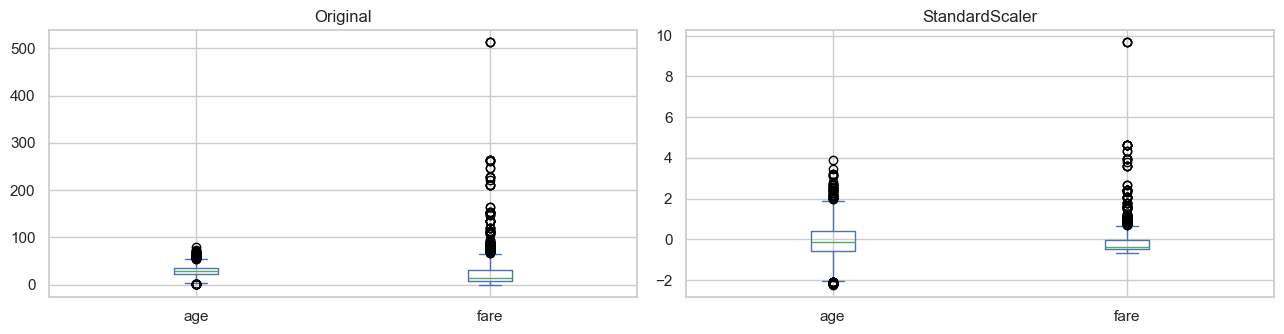

In [16]:
std_df = pd.DataFrame(StandardScaler().fit_transform(data[num_cols]), columns=num_cols)

print("StandardScaler  -> mean ~0, std ~1")
print(std_df.describe().loc[["mean", "std", "min", "max"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for a, d, t in zip(ax, [data[num_cols], std_df], ["Original", "StandardScaler"]):
    d.plot(kind="box", ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

## Step 5: Train/test split, then scale (no data leakage)

The scaler must **learn the mean and standard deviation from the training set only**, then apply them to the test set. Fitting on the full data would leak test information into training.

In [17]:
X = data.drop(columns="survived")
y = data["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit + transform on train
X_test_s[num_cols] = scaler.transform(X_test[num_cols])         # only transform on test

print("Train shape:", X_train_s.shape, "| Test shape:", X_test_s.shape)
X_train_s.head()

Train shape: (712, 12) | Test shape: (179, 12)


,pclass,sex,age,sibsp,parch,fare,adult_male,alone,embarked_Q,embarked_S,who_man,who_woman
692,3,1,-0.112078,0,0,0.513812,1,1,0,1,1,0
481,2,1,-0.112078,0,0,-0.662563,1,1,0,1,1,0
527,1,1,-0.112078,0,0,3.955399,1,1,0,1,1,0
855,3,0,-0.879807,0,1,-0.467874,0,0,0,1,0,1
801,2,0,0.118241,1,1,-0.115977,0,0,0,1,0,1


## Step 6: Verify the dataset is model-ready

In [19]:
print("Missing values  :", X_train_s.isnull().sum().sum())
print("Non-numeric cols:", list(X_train_s.select_dtypes(exclude="number").columns))
print("Train mean of scaled cols:", X_train_s[num_cols].mean().round(3).to_dict())
print("Train std of scaled cols :", X_train_s[num_cols].std().round(3).to_dict())

# Quick sanity check: a model trains without error on the cleaned data
model = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
print("\nLogistic Regression test accuracy:", round(accuracy_score(y_test, model.predict(X_test_s)), 3))

Missing values  : 0
Non-numeric cols: []
Train mean of scaled cols: {'age': 0.0, 'fare': -0.0}
Train std of scaled cols : {'age': 1.001, 'fare': 1.001}

Logistic Regression test accuracy: 0.838


## Result / Conclusion
- Missing values were handled (column dropped, median and mode imputation).
- Categorical variables were converted to numbers using label and one-hot encoding.
- Numeric attributes were standardised (mean 0, std 1), fitted on the training set only.
- The final dataset has no nulls and no text columns, so it is ready for any ML algorithm.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is feature engineering?**
Creating, transforming and selecting input variables so a model can learn better. It includes cleaning, handling missing values, encoding, scaling, creating new features and selecting useful ones.

**Q2. Why do we handle missing values?**
Most algorithms cannot work with NaN and raise errors. Ignoring them can also bias results.

**Q3. What are the ways to handle missing values?**
Delete rows or columns, fill with mean/median/mode, fill with a constant, forward/backward fill, or model-based imputation (KNN imputer, iterative imputer).

**Q4. When do you use mean, median and mode?**
Mean for symmetric numeric data. Median for skewed data or data with outliers (age, income). Mode for categorical data.

**Q5. Why did you drop the `deck` column?**
About 77% of its values are missing. Filling that many values would invent information, so dropping it is safer.

**Q6. Why did you use the median for `age`?**
Age has outliers and is slightly skewed, and the median is not affected by extreme values, unlike the mean.

**Q7. What are the types of missing data?**
MCAR (missing completely at random), MAR (missing at random, depends on other observed variables) and MNAR (missing not at random, depends on the missing value itself).

**Q8. What is the difference between label encoding and one-hot encoding?**
Label encoding assigns an integer to each category (0, 1, 2) and suits ordinal or binary data. One-hot creates a separate 0/1 column per category and suits nominal data because it does not imply any order.

**Q9. What is the dummy variable trap?**
If you keep all one-hot columns, one column is a perfect combination of the others (perfect multicollinearity). `drop_first=True` removes one column to avoid this.

**Q10. What is ordinal encoding?**
Mapping ordered categories to integers that keep the order, for example Low=0, Medium=1, High=2.

**Q11. Why is scaling needed?**
Features with large ranges (fare in hundreds) can dominate features with small ranges (age). Distance-based and gradient-based algorithms (KNN, SVM, K-Means, PCA, logistic regression, neural networks) need scaled data.

**Q12. Difference between standardisation and normalisation?**
Standardisation: $z = (x - \mu)/\sigma$, giving mean 0 and std 1. Normalisation (min-max): $x' = (x - x_{min})/(x_{max} - x_{min})$, giving values in [0, 1].

**Q13. Which algorithms do not need scaling?**
Tree-based models: Decision Tree, Random Forest, Gradient Boosting.

**Q14. How do outliers affect scaling?**
Min-max scaling is very sensitive to outliers (one huge value squeezes the others). StandardScaler is less affected. RobustScaler uses median and IQR and is the most robust.

**Q15. What is data leakage?**
When information from the test data influences training, for example fitting the scaler on the whole dataset before splitting. It gives falsely good results.

**Q16. What is the difference between `fit`, `transform` and `fit_transform`?**
`fit` learns parameters (mean, std), `transform` applies them, `fit_transform` does both in one step. Use `fit_transform` on train and only `transform` on test.

**Q17. What is a categorical vs numerical variable?**
Categorical holds labels or groups (sex, city). Numerical holds measurable numbers (age, fare); it can be discrete (count) or continuous (height).

**Q18. How do you detect missing values in pandas?**
`df.isnull().sum()` gives counts per column, `df.info()` shows non-null counts, and `sns.heatmap(df.isnull())` shows them visually.

**Q19. What is the difference between feature selection and feature extraction?**
Selection keeps a subset of original features. Extraction creates new features from the old ones (for example PCA).

**Q20. What is a pipeline and why is it useful?**
`sklearn.pipeline.Pipeline` chains steps (imputer, encoder, scaler, model) so they run in order and automatically avoid leakage.

## B. Questions about the graphs

**G1. What does the missing-values heatmap show?**
Rows are samples, columns are features, and yellow marks missing cells. It shows which columns have many gaps (`deck` almost fully missing, `age` scattered) and whether missingness is concentrated.

**G2. What does the boxplot of `age` and `fare` before scaling tell you?**
The two features have very different ranges (fare up to about 500, age up to 80), and `fare` has many outliers (dots above the whisker). That is why scaling is needed.

**G3. What does the histogram of `fare` show?**
It is right-skewed: most passengers paid a low fare, and a few paid very high amounts. For such data the median is a better centre than the mean, and a log transform can reduce skew.

**G4. What changed in the boxplots after scaling?**
Both features now sit on a comparable scale (StandardScaler is centred at 0, MinMax is in [0, 1]), but the shape of the distribution and the outliers are unchanged. Scaling changes range, not shape.

**G5. Does scaling remove outliers?**
No. It only rescales the values; outliers remain.

## C. Code questions

**C1. What does `df['age'].fillna(df['age'].median())` do?**
It replaces every NaN in `age` with the median of that column.

**C2. Why `mode()[0]`?**
`mode()` returns a Series (there can be ties), so `[0]` takes the first most frequent value.

**C3. What does `pd.get_dummies(..., drop_first=True)` do?**
It one-hot encodes the chosen columns and drops the first category of each, avoiding the dummy variable trap.

**C4. Why `stratify=y` in `train_test_split`?**
It keeps the same proportion of survived and not-survived in both train and test sets.

**C5. Why scale only `age` and `fare` and not the 0/1 columns?**
Binary columns are already in [0, 1], so scaling gives no benefit and makes them harder to interpret.